In [1]:
from pathlib import Path
from datetime import timedelta
import time
import numpy as np
import pandas as pd
import polars as pl
import lightgbm as lgb
import plotly.express as px

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
PROC = ROOT / "data" / "processed"
FIG_DIR = ROOT / "reports" / "figures"

H, STEP, WINDOWS = 28, 28, 3

df = pl.read_parquet(PROC / "m5_CA_1.parquet")
seg = pl.read_parquet(PROC / "segmentacion_CA_1.parquet")
mascara = pl.read_parquet(PROC / "mascara_CA_1.parquet")
cv_base = pd.read_parquet(PROC / "cv_baselines_CA_1.parquet")

last_date = pd.Timestamp(df["date"].max())
test_start = last_date - timedelta(days=H - 1)
first_cutoff = test_start - timedelta(days=H * WINDOWS + 1)
CUTOFFS = [first_cutoff + timedelta(days=STEP * i) for i in range(WINDOWS)]

ids_validos = cv_base["unique_id"].unique().tolist()
dev = (df.filter(pl.col("date") < test_start.date())
         .with_columns(pl.col("id").cast(pl.Utf8))
         .filter(pl.col("id").is_in(ids_validos)))

print("Cortes:", [str(c.date()) for c in CUTOFFS])
print("Series:", dev["id"].n_unique(), "| filas:", f"{dev.height:,}")

Cortes: ['2016-01-31', '2016-02-28', '2016-03-27']
Series: 3041 | filas: 4,701,626


In [2]:
LAGS = [28, 35, 42, 49, 56]

feats = (
    dev.join(mascara.select(["id", "date", "excluir"]), on=["id", "date"], how="left")
    .with_columns(pl.col("excluir").fill_null(False))
    .sort(["id", "date"])
    .with_columns([pl.col("sales").shift(l).over("id").alias(f"lag_{l}") for l in LAGS])
    .with_columns(
        rm_7=pl.col("lag_28").rolling_mean(7).over("id"),
        rm_28=pl.col("lag_28").rolling_mean(28).over("id"),
        rm_56=pl.col("lag_28").rolling_mean(56).over("id"),
        rm_112=pl.col("lag_28").rolling_mean(112).over("id"),
        rstd_28=pl.col("lag_28").rolling_std(28).over("id"),
        ceros_28=(pl.col("lag_28") == 0).cast(pl.Float32).rolling_mean(28).over("id"),
        excl_28=pl.col("excluir").cast(pl.Float32).shift(28).rolling_mean(28).over("id"),
        # Calendario
        dia_semana=pl.col("date").dt.weekday(),
        dia_mes=pl.col("date").dt.day(),
        mes=pl.col("date").dt.month(),
        semana_anio=pl.col("date").dt.week(),
        navidad=((pl.col("date").dt.month() == 12) & (pl.col("date").dt.day() == 25)).cast(pl.Int8),
        # Edad del producto (días desde su primer precio registrado)
        edad=(pl.col("date") - pl.col("date").min().over("id")).dt.total_days(),
        # Precio relativo a su media histórica acumulada (sin mirar al futuro) y cambio semanal
        precio_rel=pl.col("sell_price")
                   / (pl.col("sell_price").cum_sum() / pl.col("sell_price").cum_count()).over("id"),
        precio_cambio=pl.col("sell_price") / pl.col("sell_price").shift(7).over("id") - 1,
    )
)

CAT_FEATS = ["item_id", "dept_id", "event_type_1", "event_name_1"]
NUM_FEATS = ([f"lag_{l}" for l in LAGS] +
             ["rm_7", "rm_28", "rm_56", "rm_112", "rstd_28", "ceros_28", "excl_28",
              "dia_semana", "dia_mes", "mes", "semana_anio", "snap",
              "sell_price", "precio_rel", "precio_cambio", "edad"])
FEATS = CAT_FEATS + NUM_FEATS

pdf = feats.select(["id", "date", "sales", "excluir", "navidad", *FEATS]).to_pandas()
pdf["date"] = pd.to_datetime(pdf["date"]).astype("datetime64[ns]")
for c in CAT_FEATS:
    pdf[c] = pdf[c].astype(str).astype("category")
pdf[NUM_FEATS] = pdf[NUM_FEATS].astype("float32")

print(f"Filas: {len(pdf):,} | features: {len(FEATS)} | memoria: {pdf.memory_usage(deep=True).sum() / 1e9:.2f} GB")

Filas: 4,701,626 | features: 25 | memoria: 0.84 GB


In [3]:
PARAMS = dict(objective="tweedie", tweedie_variance_power=1.1,
              n_estimators=500, learning_rate=0.05, num_leaves=127, min_child_samples=100,
              subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0,
              n_jobs=-1, verbose=-1)

def backtest(nombre, train_start=None):
    salidas, modelo = [], None
    for c in CUTOFFS:
        # Entrenamiento: hasta el corte, sin días censurados (agotado/inactivo/pre-lanzamiento) ni Navidad
        tr = pdf[(pdf["date"] <= c) & (~pdf["excluir"]) & (pdf["navidad"] == 0)]
        if train_start is not None:
            tr = tr[tr["date"] >= train_start]
        te = pdf[(pdf["date"] > c) & (pdf["date"] <= c + timedelta(days=H))]

        t0 = time.time()
        modelo = lgb.LGBMRegressor(**PARAMS)
        modelo.fit(tr[FEATS], tr["sales"], categorical_feature=CAT_FEATS)

        pred = te[["id", "date", "sales"]].copy()
        pred[nombre] = np.clip(modelo.predict(te[FEATS]), 0, None)
        pred["cutoff"] = c
        salidas.append(pred)
        print(f"{nombre} | corte {c.date()} | train {len(tr):,} filas | {time.time() - t0:.0f} s")

    out = (pd.concat(salidas)
             .rename(columns={"id": "unique_id", "date": "ds", "sales": "y"}))
    out["cutoff"] = pd.to_datetime(out["cutoff"]).astype("datetime64[ns]")
    return out, modelo

cv_todo, modelo_todo = backtest("LGB_todo")
cv_2014, modelo_2014 = backtest("LGB_2014", train_start=pd.Timestamp("2014-01-01"))

cv_lgb = cv_todo.merge(cv_2014[["unique_id", "ds", "cutoff", "LGB_2014"]],
                       on=["unique_id", "ds", "cutoff"], how="inner")
cv_lgb.to_parquet(PROC / "cv_lgb_CA_1.parquet")
cv_lgb.head()

LGB_todo | corte 2016-01-31 | train 3,856,669 filas | 70 s
LGB_todo | corte 2016-02-28 | train 3,933,014 filas | 69 s
LGB_todo | corte 2016-03-27 | train 4,011,191 filas | 71 s
LGB_2014 | corte 2016-01-31 | train 1,957,071 filas | 45 s
LGB_2014 | corte 2016-02-28 | train 2,033,416 filas | 49 s
LGB_2014 | corte 2016-03-27 | train 2,111,593 filas | 49 s


,unique_id,ds,y,LGB_todo,cutoff,LGB_2014
0,FOODS_1_001_CA_1_evaluation,2016-02-01,0,0.640582,2016-01-31,0.660614
1,FOODS_1_001_CA_1_evaluation,2016-02-02,2,0.569668,2016-01-31,0.602042
2,FOODS_1_001_CA_1_evaluation,2016-02-03,0,0.579503,2016-01-31,0.567685
3,FOODS_1_001_CA_1_evaluation,2016-02-04,3,0.578708,2016-01-31,0.591647
4,FOODS_1_001_CA_1_evaluation,2016-02-05,1,0.721281,2016-01-31,0.707737


In [4]:
for d in (cv_base, cv_lgb):
    d["ds"] = pd.to_datetime(d["ds"]).astype("datetime64[ns]")
    d["cutoff"] = pd.to_datetime(d["cutoff"]).astype("datetime64[ns]")

cv_all = cv_base.merge(cv_lgb.drop(columns="y"), on=["unique_id", "ds", "cutoff"], how="inner")
assert len(cv_all) == len(cv_base), f"Filas no coinciden: {len(cv_all)} vs {len(cv_base)}"
MODELOS = [c for c in cv_all.columns if c not in ("unique_id", "ds", "cutoff", "y")]

# Escala RMSSE idéntica a la de los baselines
train_esc = (pdf[pdf["date"] <= first_cutoff][["id", "date", "sales"]]
             .sort_values(["id", "date"]))
escala = (train_esc.assign(d2=train_esc.groupby("id")["sales"].diff() ** 2)
                   .groupby("id")["d2"].mean().rename("escala"))
escala = escala[escala > 0]

masc = mascara.select(unique_id="id", ds="date", excluir="excluir").to_pandas()
masc["ds"] = pd.to_datetime(masc["ds"]).astype("datetime64[ns]")

cvm = (cv_all.merge(escala, left_on="unique_id", right_index=True, how="inner")
             .merge(masc, on=["unique_id", "ds"], how="left"))
cvm["excluir"] = cvm["excluir"].fillna(False).astype(bool)
cvm = cvm[~((cvm["ds"].dt.month == 12) & (cvm["ds"].dt.day == 25))]

def calcular_metricas(data, modelos):
    filas = []
    for m in modelos:
        e = data["y"] - data[m]
        por_serie = (data.assign(se=e ** 2).groupby(["unique_id", "cutoff"])
                         .agg(mse=("se", "mean"), escala=("escala", "first")))
        filas.append({"modelo": m,
                      "RMSSE": np.sqrt(por_serie["mse"] / por_serie["escala"]).mean(),
                      "MAE": e.abs().mean(),
                      "Sesgo_%": -e.sum() / data["y"].sum() * 100})
    return pd.DataFrame(filas)

m_todo = calcular_metricas(cvm, MODELOS)
m_limpio = calcular_metricas(cvm[~cvm["excluir"]], MODELOS)
comparacion = (m_todo.merge(m_limpio, on="modelo", suffixes=("_todo", "_limpio"))
               [["modelo", "RMSSE_limpio", "Sesgo_%_limpio", "MAE_limpio",
                 "RMSSE_todo", "Sesgo_%_todo"]]
               .sort_values("RMSSE_limpio").reset_index(drop=True))
comparacion.to_csv(ROOT / "reports" / "metricas_lgb_vs_baselines_CA_1.csv", index=False)
comparacion.round(3)

,modelo,RMSSE_limpio,Sesgo_%_limpio,MAE_limpio,RMSSE_todo,Sesgo_%_todo
0,LGB_todo,0.727,0.480,1.115,0.727,10.167
1,LGB_2014,0.730,-0.220,1.119,0.729,8.951
2,AutoETS,0.740,-4.746,1.133,0.697,-1.623
3,CrostonOptimized,0.746,-2.476,1.164,0.735,6.571
4,WindowAverage,0.748,-5.648,1.148,0.701,-2.624
5,TSB,0.749,-3.316,1.154,0.701,-0.557
6,SeasonalNaive,0.973,-6.706,1.364,0.912,-4.303
7,Naive,1.004,22.746,1.621,0.941,25.847


In [5]:
clases = seg.select(unique_id=pl.col("id").cast(pl.Utf8), sb_class="sb_class", abc="abc").to_pandas()
cvc = cvm[~cvm["excluir"]].merge(clases, on="unique_id", how="left")

def rmsse_por(data, grupo, modelos):
    res = []
    for m in modelos:
        tmp = (data.assign(se=(data["y"] - data[m]) ** 2)
                   .groupby([grupo, "unique_id", "cutoff"])
                   .agg(mse=("se", "mean"), escala=("escala", "first")).reset_index())
        tmp["rmsse"] = np.sqrt(tmp["mse"] / tmp["escala"])
        res.append(tmp.groupby(grupo)["rmsse"].mean().rename(m))
    tabla = pd.concat(res, axis=1)
    tabla["n_series"] = data.groupby(grupo)["unique_id"].nunique()
    return tabla

ver = ["AutoETS", "CrostonOptimized", "TSB", "WindowAverage", "LGB_todo", "LGB_2014"]
por_clase = rmsse_por(cvc, "sb_class", ver)
por_abc = rmsse_por(cvc, "abc", ver)
por_clase.to_csv(ROOT / "reports" / "rmsse_por_clase_lgb_CA_1.csv")
por_abc.to_csv(ROOT / "reports" / "rmsse_por_abc_lgb_CA_1.csv")

display(por_clase.round(3).style.highlight_min(axis=1, subset=ver, color="#c6efce"))
display(por_abc.round(3).style.highlight_min(axis=1, subset=ver, color="#c6efce"))

,AutoETS,CrostonOptimized,TSB,WindowAverage,LGB_todo,LGB_2014,n_series
sb_class,,,,,,,
erratic,0.662000,0.673000,0.662000,0.658000,0.634000,0.632000,76
intermittent,0.748000,0.754000,0.757000,0.756000,0.738000,0.740000,2140
lumpy,0.716000,0.715000,0.719000,0.720000,0.703000,0.707000,538
smooth,0.742000,0.776000,0.775000,0.769000,0.718000,0.721000,231


,AutoETS,CrostonOptimized,TSB,WindowAverage,LGB_todo,LGB_2014,n_series
abc,,,,,,,
A,0.747000,0.756000,0.761000,0.761000,0.724000,0.727000,1208
B,0.753000,0.757000,0.761000,0.760000,0.741000,0.744000,917
C,0.715000,0.721000,0.719000,0.718000,0.719000,0.719000,860


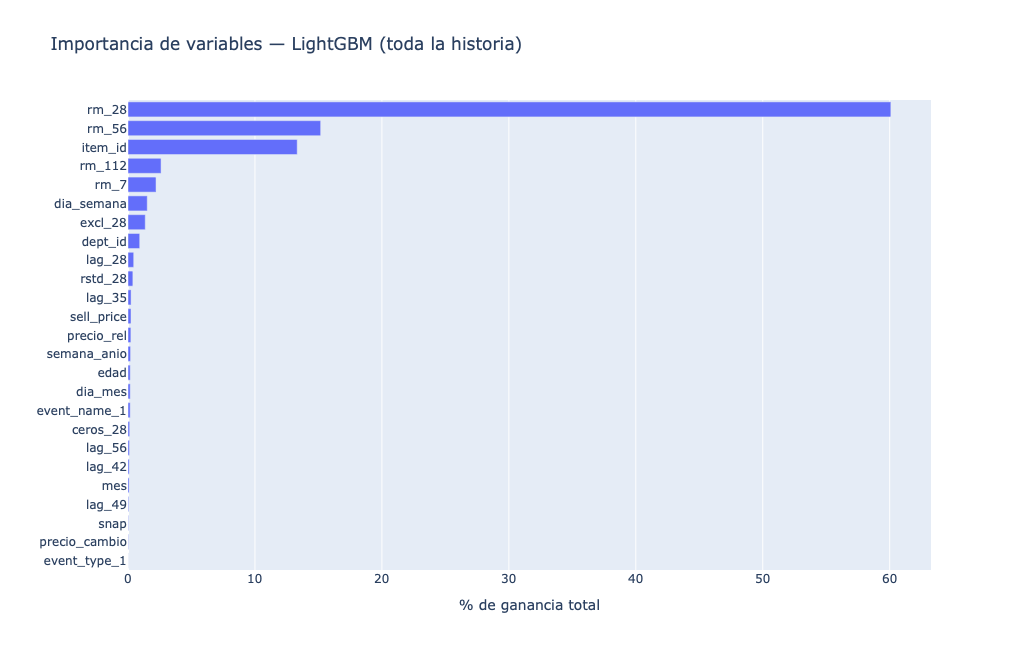

In [6]:
imp = (pd.DataFrame({"feature": FEATS,
                     "gain": modelo_todo.booster_.feature_importance(importance_type="gain")})
         .assign(gain_pct=lambda d: d["gain"] / d["gain"].sum() * 100)
         .sort_values("gain_pct"))

fig = px.bar(imp, x="gain_pct", y="feature", orientation="h",
             labels={"gain_pct": "% de ganancia total", "feature": ""},
             title="Importancia de variables — LightGBM (toda la historia)")
fig.update_layout(height=650, width=900)
fig.write_html(FIG_DIR / "07_lgb_importancia.html", include_plotlyjs="cdn")
try:
    fig.write_image(FIG_DIR / "07_lgb_importancia.png", scale=2)
except Exception as e:
    print(f"PNG no generado ({e})")
fig.show()

In [7]:
## Hallazgos de LightGBM — CA_1 (3 ventanas de 28 días, métricas sin días censurados)

#1. **LightGBM supera a todos los baselines:** RMSSE 0.727 vs. 0.740 de AutoETS (−1.8%). La mejora en error es modesta; los baselines suavizados ya están cerca del techo que impone el ruido diario a nivel producto.
#2. **El aporte principal es eliminar el sesgo:** +0.5% vs. entre −2.5% y −5.6% en los baselines. Entrenar sin días censurados corrige el subpronóstico sistemático de la demanda real.
#3. **La ganancia se concentra donde importa:** −3.1% de RMSSE en productos A y mejoras en las 4 clases de demanda; en productos C empata con un promedio suavizado.
#4. **La historia completa no estorba:** entrenar desde 2014 da el mismo resultado (0.730 vs. 0.727) con la mitad de los datos.
#5. **El nivel reciente explica casi todo:** las medias móviles de 28 y 56 días y la identidad del producto concentran ~90% de la ganancia; calendario, eventos y SNAP aportan poco a nivel producto.